In [ ]:
import matplotlib.pyplot as plt
import os
import numpy as np
import json

In [ ]:
fontsize_legend = 16
fontsize_label = 24
fontsize_ticks = 22

In [ ]:
method2name = {
    'Random': 'Random',
    'RoundRobin': 'RoundRobin',
    'Li2024-WithoutCapacityConstraints-V=0.01': r'eGLB_U',
    'Li2024-WithoutCapacityConstraints-V=0.1': r'eGLB_U',
    'Li2024-WithoutCapacityConstraints-V=1': r'eGLB_U',
    'Li2024-WithoutCapacityConstraints-V=10': r'eGLB_U',
    'Li2024-WithoutCapacityConstraints-V=100': r'eGLB_U',
    'Li2024-AllDemandsExecuted': 'eGLB',
    'STOP-V=250': 'STOP',
    'STOP-V=750': 'STOP',
    'STOP-V=1000': 'STOP',
}
method2color = {
    'Random': [.8, .8, 0],
    'RoundRobin': [1, .6, 0],
    'STOP-V=250': [1, 0, .3,],
    'STOP-V=750': [1, 0, .3],
    'STOP-V=1000': [1, 0, .3],
    'Li2024-WithoutCapacityConstraints-V=0.01': [0, .5, 1],
    'Li2024-WithoutCapacityConstraints-V=0.1': [0, .5, 1],
    'Li2024-WithoutCapacityConstraints-V=1': [0, .5, 1],
    'Li2024-WithoutCapacityConstraints-V=10': [0, .5, 1],
    'Li2024-WithoutCapacityConstraints-V=100': [0, .5, 1],
    'Li2024-AllDemandsExecuted': [0, .6, .6]
}

In [ ]:
def get_path(model, method, n_m, max_d, id, C_avg=None, R_avg=None):
    folder = 'results_alien_et' if 'STOP' in method else 'results_new'
    path = f'{folder}/{model}/{method}/n_m={n_m}-max_d={max_d}'
    if 'STOP' in method or 'Li' in method:
        path += f'/C_avg={C_avg}-R_avg={R_avg}'
    path += f'/id={id}'
    return path

In [ ]:
def get_data(path):
    data = dict()
    for t in range(300):
        if os.path.isfile(f'{path}/t={t}.json'):
            with open(f'{path}/t={t}.json', 'r') as f:
                d = json.load(f)
            keys = list(d.keys())
            for key in keys:
                if key not in data:
                    data[key] = list()
                data[key].append(d[key])
        else:
            print(f'File {path}/t={t}.json does not exist.')
            break
    for key in keys:
        try:
            data[key] = np.asarray(data[key]).astype('float32')
        except:
            pass
    elapsed_time = np.asarray(data['elapsed_time'])
    return {
        'elapsed_time': elapsed_time.mean().item(),
        'all_elapsed_time': elapsed_time,
    }

In [ ]:
def open_data(model, methods, machines, seeds, max_d, C_avg, R_avg):
    method2n_m2data = dict()
    for method in methods:
        method2n_m2data[method] = dict()
        for n_m in machines:
            method2n_m2data[method][n_m] = dict()
            for s in seeds:
                d = get_data(get_path(model, method, n_m, max_d, s, C_avg, R_avg))
                for k in d:
                    if k not in method2n_m2data[method][n_m]:
                        method2n_m2data[method][n_m][k] = list()
                    method2n_m2data[method][n_m][k].append(d[k])
    return method2n_m2data

In [ ]:
metrics = ['elapsed_time']

In [ ]:
def get_positions(machines, methods, gap=.1):
    positions = {}
    for i, n_m in enumerate(machines):
        positions[n_m] = {}
        base = i * (len(methods) + gap)
        for j, method in enumerate(methods):
            positions[n_m][method] = base + j
    return positions

In [ ]:
def plot_single(model, machines, methods, seeds, max_d, C_avg, R_avg):
    method2n_m2data = open_data(model, methods, machines, seeds, max_d, C_avg, R_avg)
    positions = get_positions(machines, methods)
    width = .5
    for metric in metrics:
        plt.figure(figsize=(7, 4))
        for method in methods:
            data = [method2n_m2data[method][n_m][metric] for n_m in machines]
            pos = [positions[n_m][method] for n_m in machines]
            plt.boxplot(data, positions=pos, 
                medianprops=dict(color='black'), 
                boxprops=dict(facecolor=method2color[method], color=method2color[method]),
                capprops=dict(color=method2color[method]),
                whiskerprops=dict(color=method2color[method]),
                flierprops=dict(color=method2color[method], markeredgecolor=method2color[method]),
                label=method2name[method],
                widths=width, patch_artist=True)
        for i in range(len(machines) - 1):
            rightmost = max(positions[machines[i]].values())
            leftmost = min(positions[machines[i+1]].values())
            sep = (rightmost + leftmost) / 2
            plt.axvline(sep, color='black', linestyle='-', linewidth=1, alpha=.3)
        plt.tick_params(axis='y', labelsize=fontsize_ticks)
        plt.xticks([np.mean([positions[n_m][m] for m in methods]) for n_m in machines], labels=machines, fontsize=fontsize_ticks)
        plt.xlabel("Machines", fontsize=fontsize_label)
        ncols = 1
        plt.ylim((-5, None))
        plt.ylabel("Elapsed Time (s)", fontsize=fontsize_label)
        plt.legend(fontsize=fontsize_legend, ncols=ncols)
        plt.tight_layout()
        # os.makedirs(f'plots/{model}', exist_ok=True)
        # plt.savefig(f'plots/{model}/max_d={max_d}-C_avg={C_avg}-R_avg={R_avg}-metric={metric}.pdf', bbox_inches='tight')
        plt.show()
        plt.close()

In [ ]:
seeds = list(set(range(30)) - set([1, 15, 16, 19, 23, 29]))
model = 'Yolo'
machines = range(3, 8)
methods = [
    # 'Random', 'RoundRobin',
    # 'STOP-V=250',
    'STOP-V=750',
    # 'STOP-V=1000',
    # 'Li2024-WithoutCapacityConstraints-V=0.01',
    # 'Li2024-WithoutCapacityConstraints-V=0.1',
    # 'Li2024-WithoutCapacityConstraints-V=1',
    # 'Li2024-WithoutCapacityConstraints-V=10',
    # 'Li2024-WithoutCapacityConstraints-V=100',
    'Li2024-AllDemandsExecuted',
]
max_d = 1000
C_avg = .001
R_avg = 2
plot_single(model, machines, methods, seeds, max_d, C_avg, R_avg)

In [ ]:
method2n_m2data = open_data(model, methods, machines, seeds, max_d, C_avg, R_avg)
n_m = 3
for s in range(len(seeds)):
    plt.figure(figsize=(5, 2))
    plt.title(f'Machines: {n_m}, Seed: {s}' )
    bins_stop, hist_stop, _ = plt.hist(
        np.asarray(method2n_m2data[methods[0]][n_m]['all_elapsed_time'][s]),
        cumulative=True, density=True,
        color=[1, 0, .3], alpha=.5, label='STOP'
    )
    bins_Li, hist_Li, _ = plt.hist(
        np.asarray(method2n_m2data[methods[1]][n_m]['all_elapsed_time'][s]),
        cumulative=True, density=True,
        color=[0, .5, 1], alpha=.5, label='eGLB'
    )
    plt.yticks(ticks=np.arange(0, 1.1, .2), labels=range(0, 101, 20))
    plt.axvline(np.mean(method2n_m2data[methods[0]][n_m]['all_elapsed_time'][s]), color=[1, 0, .3], linestyle='--')
    plt.axvline(np.mean(method2n_m2data[methods[1]][n_m]['all_elapsed_time'][s]), color=[0, .5, 1], linestyle='--')
    # plt.fill_between(max(hist_stop), max(hist_Li))
    # plt.xlim((0, 30))
    plt.xscale('log')
    plt.grid(True)
    plt.legend()
    plt.xlabel('Execution Time (s)')
    plt.ylabel('% Solved Instances')
    plt.tight_layout()
    plt.show()
    plt.close()

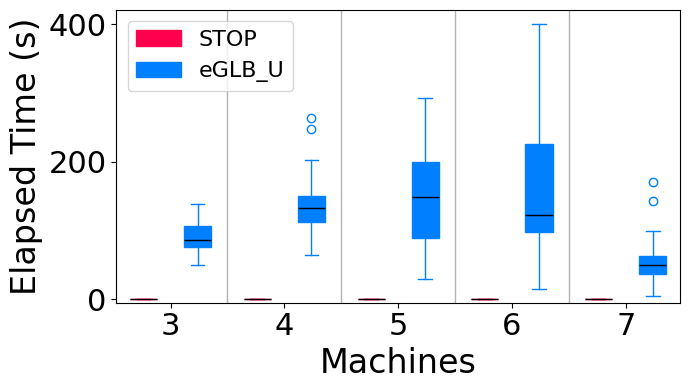

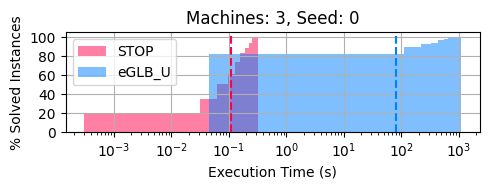

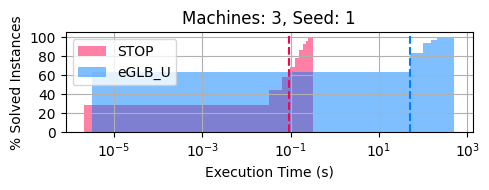

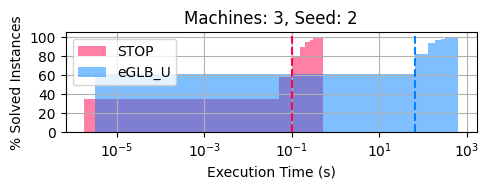

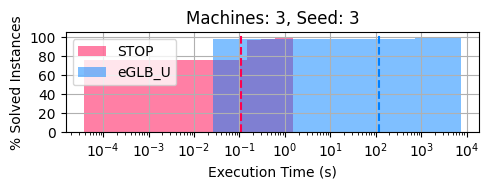

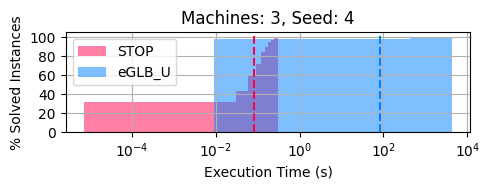

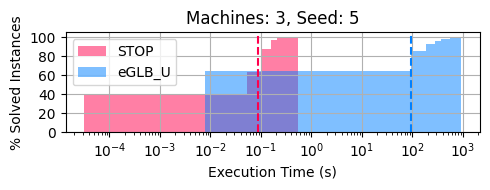

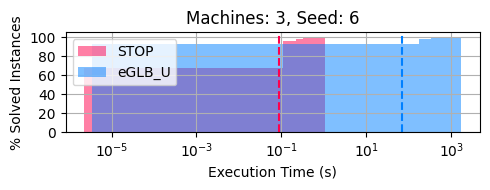

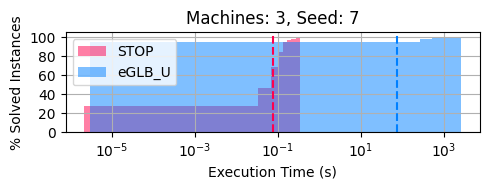

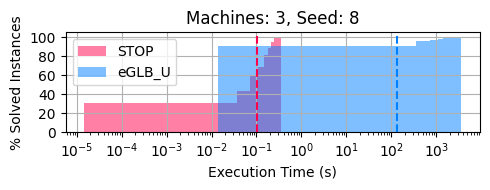

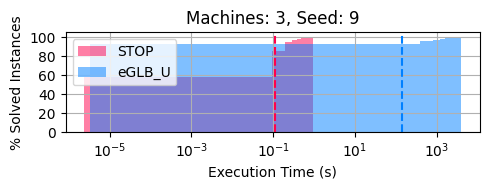

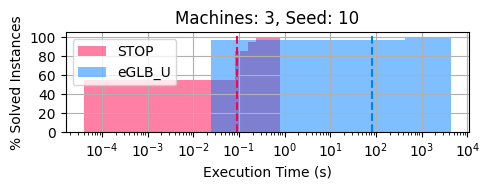

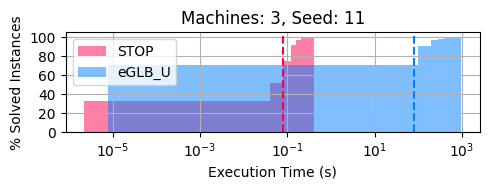

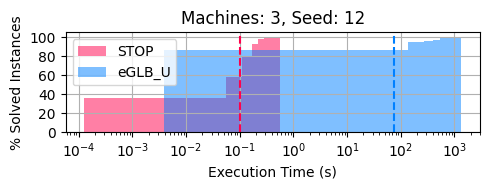

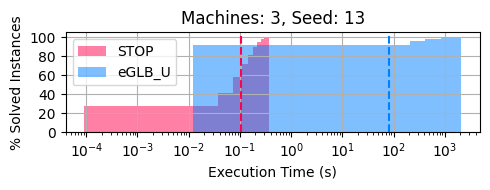

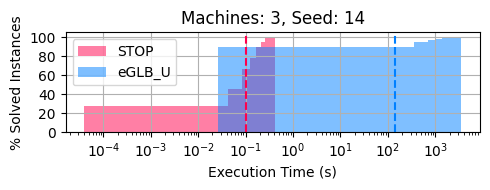

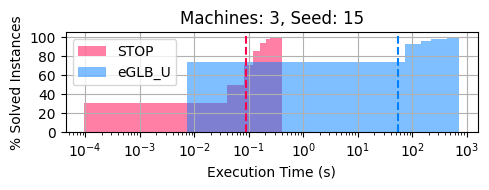

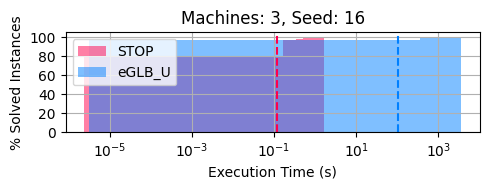

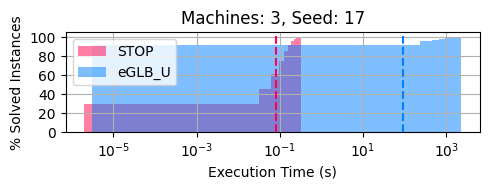

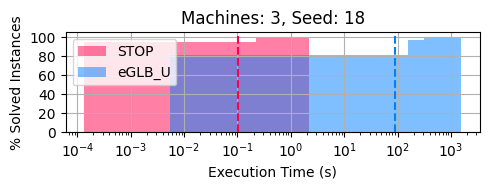

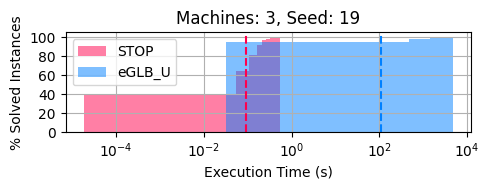

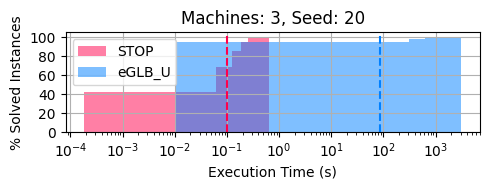

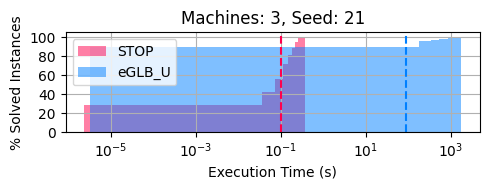

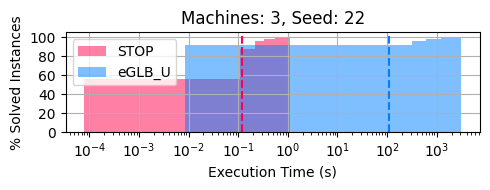

In [17]:
seeds = list(set(range(30)) - set([7, 10, 11, 12, 19, 21, 29]))
model = 'Whisper3'
machines = range(3, 8)
methods = [
    'STOP-V=1000',
    'Li2024-WithoutCapacityConstraints-V=100'
]
max_d = 1000
C_avg = .025
R_avg = 2
plot_single(model, machines, methods, seeds, max_d, C_avg, R_avg)

method2n_m2data = open_data(model, methods, machines, seeds, max_d, C_avg, R_avg)
n_m = 3
for s in range(len(seeds)):
    plt.figure(figsize=(5, 2))
    plt.title(f'Machines: {n_m}, Seed: {s}' )
    bins_stop, hist_stop, _ = plt.hist(
        np.asarray(method2n_m2data[methods[0]][n_m]['all_elapsed_time'][s]),
        cumulative=True, density=True,
        color=[1, 0, .3], alpha=.5, label='STOP'
    )
    bins_Li, hist_Li, _ = plt.hist(
        np.asarray(method2n_m2data[methods[1]][n_m]['all_elapsed_time'][s]),
        cumulative=True, density=True,
        color=[0, .5, 1], alpha=.5, label='eGLB_U'
    )
    plt.axvline(np.mean(method2n_m2data[methods[0]][n_m]['all_elapsed_time'][s]), color=[1, 0, .3], linestyle='--')
    plt.axvline(np.mean(method2n_m2data[methods[1]][n_m]['all_elapsed_time'][s]), color=[0, .5, 1], linestyle='--')
    plt.yticks(ticks=np.arange(0, 1.1, .2), labels=range(0, 101, 20))
    # plt.fill_between(max(hist_stop), max(hist_Li))
    # plt.xlim((0, 30))
    plt.xscale('log')
    plt.grid(True)
    plt.legend()
    plt.xlabel('Execution Time (s)')
    plt.ylabel('% Solved Instances')
    plt.tight_layout()
    plt.show()
    plt.close()